# Titanic Survival Prediction (v2)

Predict whether a passenger survived the Titanic sinking from details like ticket class, sex, age and family aboard.

**Why there's a v2.** My first version reported 98.8% test accuracy. When I audited it, the number turned out not to be real:

1. **Label leakage.** It trained and tested on `tested.csv`, a copy of Kaggle's *test* set. Its `Survived` column isn't real outcomes; it comes from Kaggle's `gender_submission.csv`, a sample answer that marks every woman as survived and every man as not. The model simply learned *sex = survival*. (The tell: 36.4% of that file is marked survived, exactly the share of women in it, 152 of 418.)
2. **Preprocessing fitted on the test set.** `fit_transform` was called on the test data, so the scaler learned from data the model should never see.
3. **An ID column used as a feature.** `PassengerId` is a row number, not information about a passenger.

This version uses Kaggle's real labelled training data (891 passengers), keeps a test set the model never touches until the end, puts every preprocessing step inside a scikit-learn pipeline, and compares the models against simple baselines.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42

## 1. Load the data
Kaggle's `train.csv`: the 891 passengers whose outcome is actually known. Loaded from a public mirror so the notebook runs anywhere.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"  # same file as Kaggle's train.csv
titanic = pd.read_csv(DATA_URL)
print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Hold out a test set first
The test set is split off before any exploration, stratified so it has the same survival rate as the full data. Nothing below touches it until the final evaluation.

In [3]:
train_set, test_set = train_test_split(titanic, test_size=0.2, stratify=titanic["Survived"], random_state=SEED)
X_train, y_train = train_set.drop(columns="Survived"), train_set["Survived"]
X_test, y_test = test_set.drop(columns="Survived"), test_set["Survived"]
print(f"Train: {len(X_train)} passengers, survival rate {y_train.mean():.1%}")
print(f"Test:  {len(X_test)} passengers, survival rate {y_test.mean():.1%}")

Train: 712 passengers, survival rate 38.3%
Test:  179 passengers, survival rate 38.5%


## 3. Explore (training set only)

In [4]:
print("Missing values:")
print(X_train.isna().sum()[lambda s: s > 0])

Missing values:
Age         137
Cabin       552
Embarked      2
dtype: int64


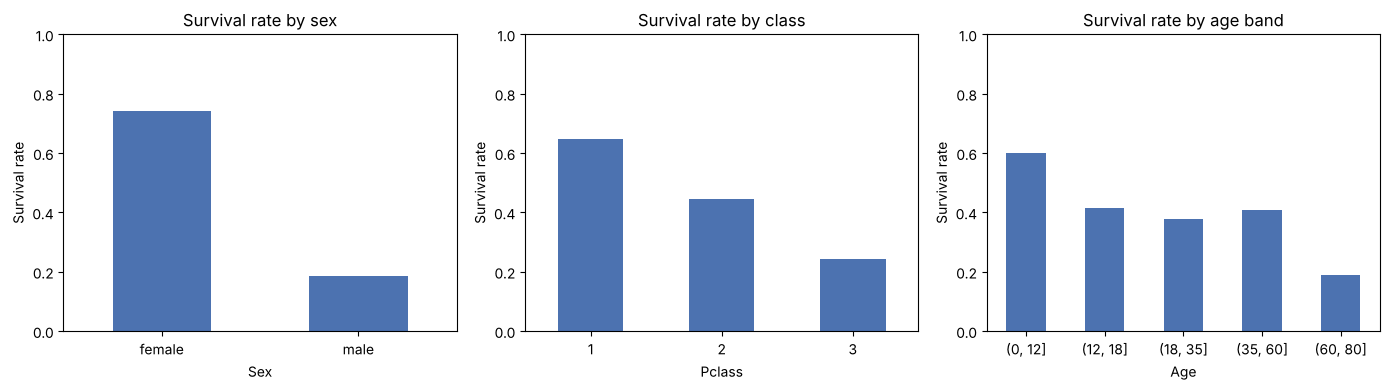

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
train_set.groupby("Sex")["Survived"].mean().plot.bar(ax=axes[0], color="#4C72B0", title="Survival rate by sex")
train_set.groupby("Pclass")["Survived"].mean().plot.bar(ax=axes[1], color="#4C72B0", title="Survival rate by class")
train_set.groupby(pd.cut(train_set["Age"], [0, 12, 18, 35, 60, 80]), observed=True)["Survived"].mean().plot.bar(
    ax=axes[2], color="#4C72B0", title="Survival rate by age band")
for ax in axes:
    ax.set_ylabel("Survival rate"); ax.set_ylim(0, 1); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**What the data shows:**
- **Sex is the strongest signal.** Women survived far more often than men ("women and children first"), so any honest model has to beat a rule that just predicts survival for women.
- **Class matters.** First-class passengers survived much more often than third-class ones.
- **Children survived more often than adults.**
- **Missing data:** `Cabin` is mostly missing, so whether a cabin is recorded becomes a yes/no feature. `Age` is about 20% missing and is filled with the median, *inside* the pipeline.

## 4. Feature engineering
New features come from columns that would otherwise be dropped. All of this happens inside the pipeline, so the training and test data are treated identically.

In [6]:
def add_features(df):
    df = df.copy()
    title = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
    title = title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    df["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
    df["HasCabin"] = df["Cabin"].notna().astype(int)
    return df

add_features(X_train).groupby("Title").size()

Title
Master     31
Miss      144
Mr        412
Mrs       107
Rare       18
dtype: int64

In [7]:
num_features = ["Age", "Fare", "FamilySize"]
cat_features = ["Pclass", "Sex", "Embarked", "Title"]
bin_features = ["IsAlone", "HasCabin"]

preprocess = Pipeline([
    ("features", FunctionTransformer(add_features)),
    ("columns", ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_features),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
        ("bin", "passthrough", bin_features),
    ], remainder="drop")),   # PassengerId, Name, Ticket and Cabin are dropped here
])

## 5. Baselines
A model only counts as good if it beats simple rules:
- **Majority class:** always predict *did not survive*.
- **Women survive:** the same rule that produced the fake 98.8% in v1.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

majority = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
women_rule_acc = ((X_train["Sex"] == "female").astype(int) == y_train).mean()
print(f"Majority-class accuracy (train): {accuracy_score(y_train, majority.predict(X_train)):.1%}")
print(f"'Women survive' rule accuracy (train): {women_rule_acc:.1%}")

Majority-class accuracy (train): 61.7%
'Women survive' rule accuracy (train): 78.9%


## 6. Compare models with 5-fold cross-validation
Cross-validation runs on the training set only. Each fold refits the whole pipeline (imputation and scaling included), so no fold sees statistics from its own validation data.

In [9]:
models = {
    "Logistic regression": LogisticRegression(max_iter=1000),
    "SVM (RBF)": SVC(random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
    "Gradient boosting": GradientBoostingClassifier(random_state=SEED),
}
rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "roc_auc"], return_train_score=True)
    rows.append({"Model": name,
                 "Train accuracy": s["train_accuracy"].mean(),
                 "CV accuracy": s["test_accuracy"].mean(),
                 "CV accuracy (std)": s["test_accuracy"].std(),
                 "CV ROC-AUC": s["test_roc_auc"].mean()})
results = pd.DataFrame(rows).set_index("Model").sort_values("CV accuracy", ascending=False)
results.round(3)

,Train accuracy,CV accuracy,CV accuracy (std),CV ROC-AUC
Model,,,,
SVM (RBF),0.853,0.831,0.019,0.867
Logistic regression,0.836,0.830,0.024,0.872
Gradient boosting,0.924,0.824,0.029,0.895
Random forest,0.986,0.823,0.013,0.876


**Reading the table:** the *gap* between train and CV accuracy is the overfitting check. An untuned random forest typically memorises the training set (train accuracy near 98%) but generalises no better than simpler models. The models are judged on CV accuracy and ROC-AUC, never on training scores.

## 7. Tune the two strongest candidates

In [10]:
searches = {
    "SVM (RBF)": GridSearchCV(
        Pipeline([("prep", preprocess), ("model", SVC(random_state=SEED))]),
        {"model__C": [0.3, 1, 3, 10], "model__gamma": ["scale", 0.03, 0.1]},
        cv=cv, scoring="accuracy"),
    "Gradient boosting": GridSearchCV(
        Pipeline([("prep", preprocess), ("model", GradientBoostingClassifier(random_state=SEED))]),
        {"model__n_estimators": [100, 200], "model__max_depth": [2, 3], "model__learning_rate": [0.05, 0.1]},
        cv=cv, scoring="accuracy"),
}
for name, gs in searches.items():
    gs.fit(X_train, y_train)
    print(f"{name}: best CV accuracy {gs.best_score_:.3f} with {gs.best_params_}")

best_name = max(searches, key=lambda n: searches[n].best_score_)
final_model = searches[best_name].best_estimator_
print(f"\nSelected model: {best_name}")

SVM (RBF): best CV accuracy 0.837 with {'model__C': 3, 'model__gamma': 0.03}


Gradient boosting: best CV accuracy 0.827 with {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200}

Selected model: SVM (RBF)


## 8. Final evaluation on the untouched test set
The selected model was refit on the full training set by `GridSearchCV`. It is scored once on the 179 test passengers. No retraining on test data.

In [11]:
y_pred = final_model.predict(X_test)
# SVMs output a decision score rather than a probability; both work for ROC-AUC
y_prob = (final_model.predict_proba(X_test)[:, 1] if hasattr(final_model, "predict_proba")
          else final_model.decision_function(X_test))
women_rule_test = ((X_test["Sex"] == "female").astype(int) == y_test).mean()

summary = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "'Women survive' baseline accuracy": women_rule_test,
}).round(3)
summary

Accuracy                             0.844
Precision                            0.825
Recall                               0.754
F1                                   0.788
ROC-AUC                              0.849
'Women survive' baseline accuracy    0.777
dtype: float64

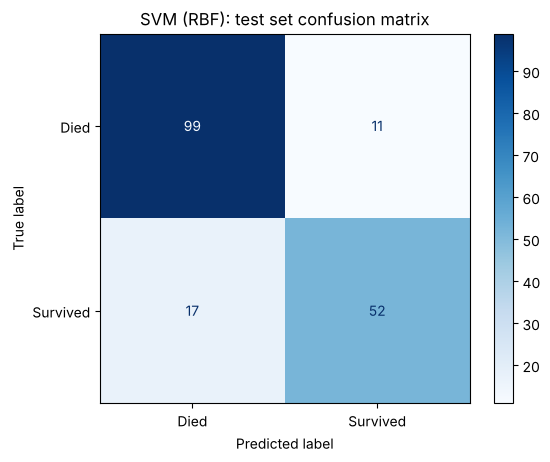

In [12]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Died", "Survived"]).plot(cmap="Blues")
plt.title(f"{best_name}: test set confusion matrix"); plt.show()

## 9. Error analysis
Which passengers does the model get wrong?

In [13]:
errors = test_set.assign(pred=y_pred, score=y_prob.round(2))
errors = errors[errors["pred"] != errors["Survived"]]
print(f"{len(errors)} misclassified passengers out of {len(test_set)}")
print(errors.groupby(["Sex", "Pclass"]).size().rename("errors"))
errors[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Survived", "score"]].head(10)

28 misclassified passengers out of 179
Sex     Pclass
female  1         1
        2         1
        3         9
male    1         9
        2         2
        3         6
Name: errors, dtype: int64


,Pclass,Sex,Age,SibSp,Parch,Fare,Survived,score
553,3,male,22.0,0,0,7.2250,1,-0.95
712,1,male,48.0,1,0,52.0000,1,-0.98
455,3,male,29.0,0,0,7.8958,1,-1.00
297,1,female,2.0,1,2,151.5500,0,1.17
40,3,female,40.0,1,0,9.4750,0,0.49
564,3,female,NaN,0,0,8.0500,0,0.65
502,3,female,NaN,0,0,7.6292,0,1.00
17,2,male,NaN,0,0,13.0000,1,-1.06
701,1,male,35.0,0,0,26.2875,1,-0.99
447,1,male,34.0,0,0,26.5500,1,-1.06


## 10. Conclusions

- **Realistic performance.** The final model beats both baselines on data it never saw, and lands in the normal range for this dataset (roughly 80–85% accuracy). The v1 figure of 98.8% came from leaked labels, not a better model.
- **Where it fails.** Most errors fall on passengers the "women and children first" pattern doesn't explain: men who survived, and third-class women who didn't. That information isn't in these features.
- **Lessons I now apply to every model:**
  1. Check where the labels come from.
  2. Split off the test set before exploring or preprocessing.
  3. Keep every transformation inside a pipeline.
  4. Always compare against a simple baseline.
  5. Treat an unusually high score as a bug until proven otherwise.